In [29]:
# Importing main libraries
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import random as rd
import matplotlib.pyplot as plt
from math import sqrt

In [30]:
data = pd.read_csv("Mall_Customers.csv")
data.head()

,CustomerID,Gender,Age,Annual_In,Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


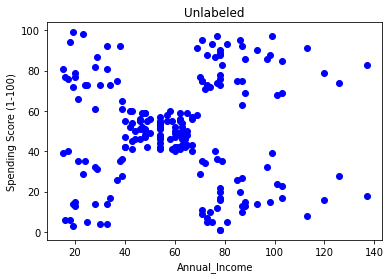

In [31]:
X = data[["Annual_In", "Spending Score (1-100)"]]
# Visualize data point
plt.scatter(X["Annual_In"], X["Spending Score (1-100)"], c="blue")
plt.xlabel("Annual_Income")
plt.ylabel("Spending Score (1-100)")
plt.title("Unlabeled")
plt.show()

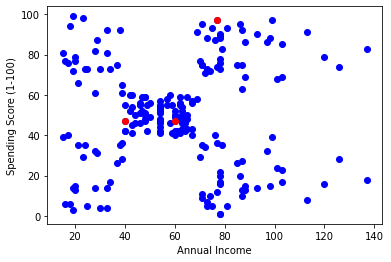

In [32]:
# step 1 and 2

# number of centriod
K=3

# select random observation as a centriod 
Centroids = (X.sample(n=K))
plt.scatter(X["Annual_In"], X["Spending Score (1-100)"], c="blue")
plt.scatter(Centroids["Annual_In"], Centroids["Spending Score (1-100)"], c="red")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score (1-100)")
plt.show()

In [33]:
Centroids

,Annual_In,Spending Score (1-100)
145,77,97
96,60,47
47,40,47


In [34]:
# Step 3 - Assign all the points to the closest cluster centroid
# Step 4 - Recompute centroids of newly formed clusters
# Step 5 - Repeat step 3 and 4

diff = 1
j=0

while(diff!=0):
    XD=X
    i=1
    for index1, row_c in Centroids.iterrows():
        ED=[]
        for index2, row_d in XD.iterrows():
            d1 = (row_c["Annual_In"]-row_d["Annual_In"])**2
            d2 = (row_c["Spending Score (1-100)"]-row_d["Spending Score (1-100)"])**2
            d = sqrt(d1+d2)
            ED.append(d)
        X[i] = ED
        i = i+1
    
    C = []
    for index, row in X.iterrows():
        min_dist=row[1]
        pos=1
        for i in range(K):
            if row[i+1] < min_dist:
                min_dist = row[i+1]
                pos = i+1
        C.append(pos)
    X["Cluster"]=C
    Centroids_new = X.groupby(["Cluster"]).mean()[["Spending Score (1-100)", "Annual_In"]]
    if j == 0:
        diff = 1
        j = j+1
    else:
        diff = (Centroids_new['Spending Score (1-100)'] - Centroids['Spending Score (1-100)']).sum() +
        (Centroids_new['Annual_In'] - Centroids['Annual_In']).sum()
        print(diff.sum())
    Centroids = X.groupby(["Cluster"]).mean()[["Spending Score (1-100)","Annual_In"]]

<ipython-input-34-e95f04f9c20a>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[i] = ED


5.109082892416232
2.019087252046063
1.384177230385088
0.825036109619866
0.7339317082765291
0.9550261426884781
0.09651713187423283
0.0


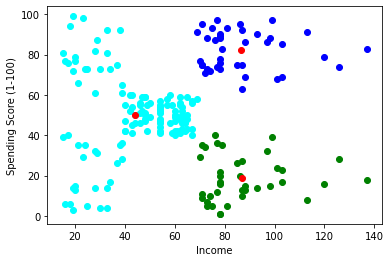

In [35]:
color=['blue','green','cyan']
for k in range(K):
    data=X[X["Cluster"]==k+1]
    plt.scatter(data["Annual_In"],data["Spending Score (1-100)"],c=color[k])
plt.scatter(Centroids["Annual_In"],Centroids["Spending Score (1-100)"],c='red')
plt.xlabel('Income')
plt.ylabel('Spending Score (1-100)')
plt.show()